In [2]:
from unstructured.partition.pdf import partition_pdf

output_path = "./content/"
file_path = './docs/Report.pdf'

# Reference: https://docs.unstructured.io/open-source/core-functionality/chunking
chunks = partition_pdf(
  filename=file_path,
  infer_table_structure=True,            # extract tables
  strategy="hi_res",                     # mandatory to infer tables

  extract_image_block_types=["Image"],   # Add 'Table' to list to extract image of tables
  # image_output_dir_path=output_path,   # if None, images and tables will saved in base64

  extract_image_block_to_payload=True,   # if true, will extract base64 for API usage

  chunking_strategy="by_title",          # or 'basic'
  max_characters=10000,                  # defaults to 500
  combine_text_under_n_chars=2000,       # defaults to 0
  new_after_n_chars=6000,

  # extract_images_in_pdf=True,          # deprecated
)

c:\Users\rajde\anaconda3\envs\langchain\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Could not get FontBBox from font descriptor because None cannot be parsed as 4 floats
Could not get FontBBox from font descriptor because None cannot be parsed as 4 floats
Could not get FontBBox from font descriptor because None cannot be parsed as 4 floats
Could not get FontBBox from font descriptor because None cannot be parsed as 4 floats
Could not get FontBBox from font descriptor because None cannot be parsed as 4 floats
Could not get FontBBox from font descriptor because None cannot be parsed as 4 floats
No languages specified, defaulting to English.
Could not get FontBBox from font descriptor because None cannot be parsed as 4 floats
Could not get FontBBox from font descriptor because None cannot be parsed as 4 floats
Co

In [3]:
chunks[0].metadata.orig_elements

In [4]:
chunks[0].metadata.orig_elements[0].text

'—— DESAI — METROPOLIS'

In [5]:
chunks

In [6]:
import base64
from IPython.display import Image, display

def display_base64_image(base64_code):
  # Decode the base64 string to binary
  image_data = base64.b64decode(base64_code)
  # Display the image
  display(Image(data=image_data))

In [7]:
chunks[0].metadata.orig_elements

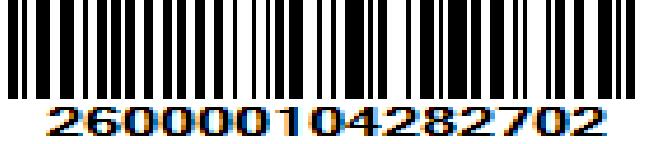

In [8]:
display_base64_image(chunks[0].metadata.orig_elements[3].metadata.image_base64)

In [9]:
chunks[1].to_dict()

{'type': 'Table',
 'element_id': 'c95344253110055ab70ecbb7f3faba50',
 'text': 'VID No. : 260000104282702 PID No. : P26426580287178 Referred by : SELF Registered On : 17/10/2026 10:06 AM Collected On : 17/10/2026 10:06AM Reported On : 17/10/2026 12:29 PM',
 'metadata': {'last_modified': '2026-11-06T22:42:29',
  'text_as_html': '<table><tr><td>VID No.</td><td>: 260000104282702</td></tr><tr><td colspan="2">PID No. : P26426580287178</td></tr><tr><td>Referred by</td><td>&gt; SELF</td></tr><tr><td>Registered On</td><td>: 17/10/2026 10:06 AM</td></tr><tr><td>Collected On</td><td>: 17/10/2026 10:06AM</td></tr><tr><td>Reported On</td><td>: 17/10/2026 12:29 PM</td></tr></table>',
  'filetype': 'application/pdf',
  'languages': ['eng'],
  'page_number': 1,
  'orig_elements': 'eJx9kl1vmzAYhf+K5YtdFbAdvpJlkaZ9adLWRW3VmzRCBr8hlgAjcLRGVf97X5Muoi2rJQQ+Pg/mHLx5oFBBDY3NtKILQos8yeNoLryZjJQXziD1csiFx3d5XBSRimcJpxeE1mClklYi80ALYzqlG2mhH+aVPJqDzfagy71FJWTzGTLP8l+t7B5Vkc4TVFujG+u4zYaHYu6jhit+tL0gZyFmiR86QeDw

In [10]:
chunks[1].metadata.orig_elements[0].to_dict()

{'type': 'Table',
 'element_id': '5e893b9a-eb96-4da9-86a6-761802255683',
 'text': 'VID No. : 260000104282702 PID No. : P26426580287178 Referred by : SELF Registered On : 17/10/2026 10:06 AM Collected On : 17/10/2026 10:06AM Reported On : 17/10/2026 12:29 PM',
 'metadata': {'detection_class_prob': 0.4175075888633728,
  'is_extracted': 'true',
  'coordinates': {'points': ((np.float64(1429.67236328125),
     np.float64(289.4585266113281)),
    (np.float64(1429.67236328125), np.float64(607.4410400390625)),
    (np.float64(2222.226318359375), np.float64(607.4410400390625)),
    (np.float64(2222.226318359375), np.float64(289.4585266113281))),
   'system': 'PixelSpace',
   'layout_width': 2897,
   'layout_height': 4093},
  'last_modified': '2026-11-06T22:42:29',
  'text_as_html': '<table><tbody><tr><td>VID No.</td><td>: 260000104282702</td></tr><tr><td colspan="2">PID No. : P26426580287178</td></tr><tr><td>Referred by</td><td>&gt; SELF</td></tr><tr><td>Registered On</td><td>: 17/10/2026 10:06

In [60]:
#### SPLIT TABLES INTO CHUNKS BASED ON SIZE AND MAKE TEXT AS KEY-VALUE RECORDS
from bs4 import BeautifulSoup
import re


MAX_CHARS = 1800


def clean_text(text):
    """Normalize whitespace without changing the actual content."""
    return re.sub(r"\s+", " ", text or "").strip()


def parse_table_html(html):
    """
    Convert an Unstructured HTML table into structured key-value records.
    Preserves section headings and handles colspan.
    """

    soup = BeautifulSoup(html, "html.parser")
    table = soup.find("table")

    if not table:
        return [], []

    records = []
    warnings = []

    current_section = ""
    table_title = ""

    rows = table.find_all("tr")

    for row_idx, row in enumerate(rows):

        cells = row.find_all(["td", "th"], recursive=False)

        if not cells:
            continue

        # Extract cell text and logical column positions.
        logical_cells = []
        column_position = 0

        for cell in cells:

            value = clean_text(cell.get_text(" ", strip=True))

            colspan = int(cell.get("colspan", 1) or 1)

            logical_cells.append({
                "position": column_position,
                "colspan": colspan,
                "value": value
            })

            column_position += colspan

        non_empty = [
            cell for cell in logical_cells
            if cell["value"]
        ]

        if not non_empty:
            continue

        row_text = " ".join(
            cell["value"] for cell in non_empty
        )

        normalized = row_text.lower()

        # Skip column header rows.
        if (
            "investigation" in normalized
            and "observed value" in normalized
        ):
            continue

        # Identify full-width rows (usually titles or section headings).
        if (
            len(non_empty) == 1
            and non_empty[0]["colspan"] >= 2
        ):

            heading = non_empty[0]["value"]

            if not table_title:
                table_title = heading
            else:
                current_section = heading

            continue

        # Handle ordinary rows using logical column positions.
        test = ""
        observed = ""
        unit = ""
        reference = ""

        for cell in non_empty:

            pos = cell["position"]
            value = cell["value"]

            if pos == 0:
                test = value

            elif pos == 1:
                observed = value

            elif pos == 2:
                unit = value

            elif pos >= 3:
                if reference:
                    reference += " " + value
                else:
                    reference = value

        if not test:
            warnings.append(
                f"Row {row_idx}: Missing test/label; "
                f"raw content: {row_text}"
            )
            continue

        # Avoid treating repeated table headers as measurements.
        if test.lower() in {
            "test", "investigation", "parameter"
        }:
            continue

        # Build a self-contained record.
        record_parts = []

        if table_title:
            record_parts.append(
                f"Table: {table_title}"
            )

        if current_section:
            record_parts.append(
                f"Section: {current_section}"
            )

        record_parts.append(f"Test: {test}")

        if observed:
            record_parts.append(
                f"Observed Value: {observed}"
            )

        if unit:
            record_parts.append(
                f"Unit: {unit}"
            )

        if reference:
            record_parts.append(
                f"Biological Reference Range: {reference}"
            )

        record = "\n".join(record_parts)

        records.append(record)

    return records, warnings


def pack_records(records, max_chars=MAX_CHARS):
    """
    Pack complete key-value records into chunks.
    Never splits an individual record.
    """

    chunks = []
    current_chunk = ""

    for record in records:

        # A single record must fit independently.
        if len(record) > max_chars:
            raise ValueError(
                f"Individual table record exceeds "
                f"{max_chars} characters. "
                f"Record length: {len(record)}. "
                f"Record: {record[:200]}"
            )

        candidate = (
            current_chunk + "\n\n" + record
            if current_chunk
            else record
        )

        if len(candidate) <= max_chars:
            current_chunk = candidate

        else:
            if current_chunk:
                chunks.append(current_chunk)

            current_chunk = record

    if current_chunk:
        chunks.append(current_chunk)

    return chunks


def get_table_coordinates(chunk):
    """
    Get the original table coordinates.
    The same coordinates will be assigned to every child chunk.
    """

    orig_elements = getattr(
        chunk.metadata, "orig_elements", None
    ) or []

    for element in orig_elements:

        coordinates = getattr(
            element.metadata, "coordinates", None
        )

        if coordinates:
            return coordinates.to_dict()

    # Fallback to table metadata.
    coordinates = getattr(
        chunk.metadata, "coordinates", None
    )

    return coordinates.to_dict() if coordinates else None


def transform_table(chunk, max_chars=MAX_CHARS):
    """
    Convert an Unstructured Table element into
    token-limited structured embedding chunks.
    """

    html = getattr(
        chunk.metadata, "text_as_html", None
    )

    if not html:
        raise ValueError(
            "Table HTML is missing. Cannot safely "
            "construct structured key-value records."
        )

    records, warnings = parse_table_html(html)

    embedding_chunks = pack_records(
        records,
        max_chars=max_chars
    )

    coordinates = get_table_coordinates(chunk)

    results = []

    for idx, text in enumerate(embedding_chunks):

        results.append({
            "type": "Table",
            "element_id": f"{chunk._element_id}_{idx}",
            "table_id": chunk._element_id,
            "text": text,
            "text_as_html": html,
            "page_number": chunk.metadata.page_number,
            "file_name": chunk.metadata.filename,
            "coordinates": coordinates,
            "last_modified": chunk.metadata.last_modified,
        })

    return results


In [101]:
import uuid
# separate tables from texts
tables = []
texts = []    ## Composite Elements

for chunk in chunks:
  if "Table" in str(type(chunk)):
    table_results = transform_table(
      chunk,
      max_chars=1800
    )

    tables.extend(table_results)

  if "CompositeElement" in str(type((chunk))):
    total_text = ""
    coordinates = []
    for element in chunk.metadata.orig_elements:
      if len(total_text) > 1800:
        texts.append({
          'type': 'Text',
          'element_id': uuid.uuid4().hex + "_" + str(len(texts)),
          'text': total_text,
          'page_number': element.metadata.page_number,
          'file_name': element.metadata.filename,
          'coordinates': coordinates,
          'last_modified': element.metadata.last_modified,
        })

        total_text = ""
        coordinates = []

      if "Image" not in str(type(element)):
        total_text += (element.text + "\n\n")
        coordinates.append(element.metadata.coordinates.to_dict() if element.metadata.coordinates else None)


    if total_text.strip():  # Only append if there's text
      texts.append({
        'type': 'Text',
        'element_id': uuid.uuid4().hex,
        'text': total_text,
        'page_number': element.metadata.page_number,
        'file_name': element.metadata.filename,
        'coordinates': coordinates,
        'last_modified': element.metadata.last_modified,
      })

In [13]:
chunks[0].metadata.orig_elements[0].to_dict()

{'type': 'Image',
 'element_id': '798f1a11-9ac2-4f80-9f25-f08494c027fa',
 'text': '—— DESAI — METROPOLIS',
 'metadata': {'coordinates': {'points': ((np.float64(75.67309551362088),
     np.float64(50.44873073130252)),
    (np.float64(75.67309551362088), np.float64(216.20885099129723)),
    (np.float64(774.7483663854835), np.float64(216.20885099129723)),
    (np.float64(774.7483663854835), np.float64(50.44873073130252))),
   'system': 'PixelSpace',
   'layout_width': 2897,
   'layout_height': 4093},
  'last_modified': '2026-11-06T22:42:29',
  'filetype': 'PNG',
  'languages': ['eng'],
  'page_number': 1,
  'image_base64': '...',
  'image_mime_type': 'image/jpeg'}}

In [127]:
chunks[0].metadata.orig_elements[0]._element_id

'798f1a11-9ac2-4f80-9f25-f08494c027fa'

In [130]:
# Get the images from the CompositeElement objects
def get_images_base64(chunks):
  images_b64 = []
  for chunk in chunks:
    if "CompositeElement" in str(type(chunk)):
      for el in chunk.metadata.orig_elements:
        if "Image" in str(type(el)):
          images_b64.append({
            'type': 'Image',
            'image_id': el._element_id or uuid.uuid4().hex,
            'base64Image': el.metadata.image_base64,
            'page_number': el.metadata.page_number,
            'file_name': el.metadata.filename,
            'coordinates': el.metadata.coordinates.to_dict() if el.metadata.coordinates else None,
            'last_modified': el.metadata.last_modified,
          })
  return images_b64

images = get_images_base64(chunks)

In [131]:
images[1]

{'type': 'Image',
 'image_id': 'eb7ad842b84447268a2275c4e149a705',
 'base64Image': '...',
 'page_number': 1,
 'file_name': None,
 'coordinates': {'points': ((np.float64(1008.9745796260573),
    np.float64(43.24177369825924)),
   (np.float64(1008.9745796260573), np.float64(223.41580569100753)),
   (np.float64(1189.1486116188055), np.float64(223.41580569100753)),
   (np.float64(1189.1486116188055), np.float64(43.24177369825924))),
  'system': 'PixelSpace',
  'layout_width': 2897,
  'layout_height': 4093},
 'last_modified': '2026-11-06T22:42:29'}

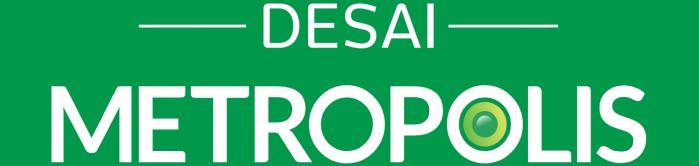

In [16]:
display_base64_image(images[0]['base64Image'])

###  Seprating images, tables and texts done

In [17]:
len(images)

10

### Testing a prescription

In [119]:
from unstructured.partition.pdf import partition_pdf

output_path = "./content/"
file_path = './docs/presc.pdf'

# Reference: https://docs.unstructured.io/open-source/core-functionality/chunking
chunks_presc = partition_pdf(
  filename=file_path,
  infer_table_structure=True,            # extract tables
  strategy="hi_res",                     # mandatory to infer tables

  extract_image_block_types=["Image"],   # Add 'Table' to list to extract image of tables
  # image_output_dir_path=output_path,   # if None, images and tables will saved in base64

  extract_image_block_to_payload=True,   # if true, will extract base64 for API usage

  chunking_strategy="by_title",          # or 'basic'
  max_characters=10000,                  # defaults to 500
  combine_text_under_n_chars=2000,       # defaults to 0
  new_after_n_chars=6000,

  # extract_images_in_pdf=True,          # deprecated
)

No languages specified, defaulting to English.


In [122]:
chunks_presc[0].metadata.orig_elements

In [131]:
chunks_presc[0].metadata.orig_elements[8].text

'Shri Pramukh Swami Maharaj M arg, Adajan Char Rasta, Adajan, Surat, a. nda Tel. : 0261 - 2708000 / 2708100 / 2781000'

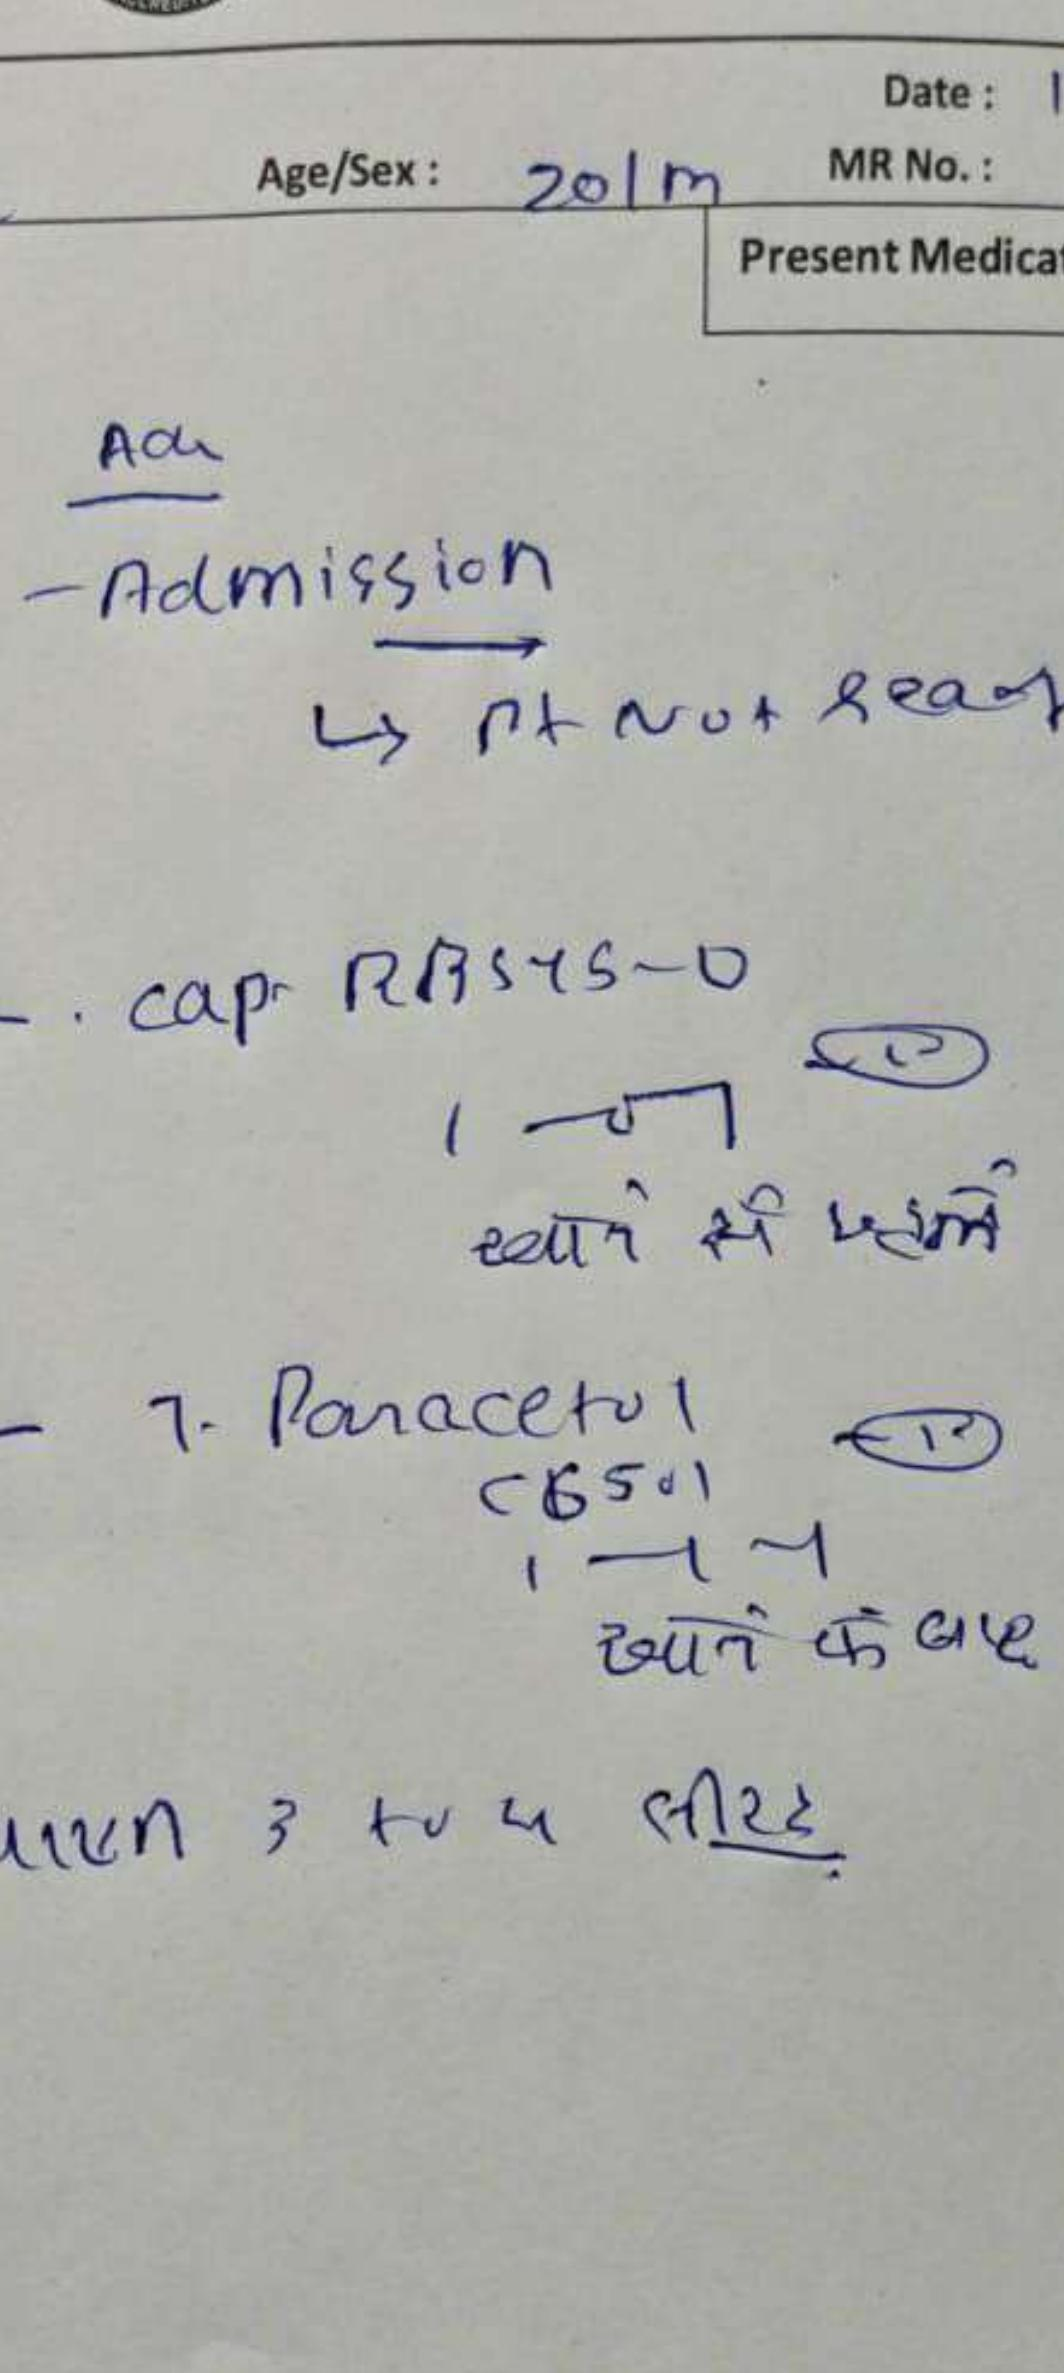

In [136]:
display_base64_image(chunks_presc[0].metadata.orig_elements[9].metadata.image_base64)

In [ ]:
from langchain_openai import ChatOpenAI
import os

model = ChatOpenAI(
  model="mistralai/mistral-large-2512",
  base_url="https://api.xkiro.com/v1",
  api_key="",
  temperature=0,
)

In [76]:
prompt_template = """You are an image analysis component in a Medical Document RAG (Retrieval-Augmented Generation) ingestion pipeline.

Your task is to analyze images extracted from medical reports, laboratory reports, prescriptions, and other healthcare-related documents.

### 1. Image Analysis

For each image:

1. Identify the type and contents of the image.
2. Determine whether it contains potentially useful medical or clinical information.
3. Classify it into one of the specified image categories.
4. Generate an appropriate summary based on the image type.
5. Preserve the accuracy of visible medical information. Never invent missing content, measurements, or details.

### 2. Classification Categories

Classify each image into one of the following:

- **RELEVANT:** Contains medical or clinical information that could be useful for understanding the patient's medical records.
- **IRRELEVANT:** Contains logos, decorative graphics, generic icons, watermarks, or unrelated visual content that does not need to be stored in the vector database.
- **UNCERTAIN:** The image is unclear, incomplete, or its medical relevance cannot be determined confidently.

### 3. Image Type Categories

Choose exactly one of the following:

- HANDWRITING
- MEDICAL_SCAN
- CLINICAL_PHOTOGRAPH
- DIAGNOSTIC_GRAPH
- CHART
- MEDICAL_ILLUSTRATION
- DOCUMENT_SCREENSHOT
- LOGO
- ICON
- DECORATIVE_IMAGE
- OTHER

### 4. Summary Generation Instructions

The summary field must be generated according to the identified image type.

**A. HANDWRITING**

This category is primarily intended for handwritten prescriptions, doctor's notes, handwritten medical instructions, and other handwritten medical content.

- Transcribe ONLY the handwritten content visible in the image.
- The summary must contain only the corrected transcription. Do not include any introductory text, headers, labels, explanations, descriptions, or concluding statements.
- Correct obvious spelling mistakes and recognize common medical terminology, drug names, dosage expressions, and abbreviations when their intended meaning is clear.
- Expand medical abbreviations and short forms into their commonly accepted full forms wherever you can do so confidently.
- Correct incorrectly recognized drug names and medical terms only when the intended word can be identified with sufficient confidence.
- Preserve the original meaning, dosage, frequency, units, and instructions.
- Do not guess illegible words, drug names, dosages, or measurements. Mark unclear portions as `[illegible]` rather than inventing a transcription.
- Preserve the original order and structure of the handwritten content as much as possible.

**Important:** For HANDWRITING, the summary field must contain ONLY the transcribed handwritten content. It must never contain phrases such as "The image contains handwritten text", "Transcription:", or "The prescription reads".

**B. All Other Image Types**

For all other image categories:

- Provide a short, informative description of the visible content.
- Identify the type of medical image, chart, graph, illustration, or document shown.
- Include relevant visible labels, annotations, measurements, and other clinical information when readable.
- Avoid unnecessary visual descriptions, speculation, or diagnostic conclusions.
- Do not infer medical findings that cannot be directly established from the image.

### 5. Important Rules

- Medical images do not need to contain readable text to be classified as RELEVANT.
- Clinical graphs and charts containing patient measurements or medical trends should be considered RELEVANT.
- A hospital logo alone should be classified as IRRELEVANT.
- Do not classify an image as RELEVANT merely because it appears inside a medical document.
- If the image contains both relevant medical information and decorative elements, prioritize the medical information.
- When uncertain about the content or transcription, do not fabricate information.

### 6. Output Format

Return ONLY valid JSON. Do not include Markdown code fences, explanations, or additional text.

Use exactly the following structure:

{{
  "classification": "RELEVANT | IRRELEVANT | UNCERTAIN",
  "image_type": "HANDWRITING | MEDICAL_SCAN | CLINICAL_PHOTOGRAPH | DIAGNOSTIC_GRAPH | CHART | MEDICAL_ILLUSTRATION | DOCUMENT_SCREENSHOT | LOGO | ICON | DECORATIVE_IMAGE | OTHER",
  "summary": "Image-specific summary or handwritten transcription"
}}

For IRRELEVANT images, return an empty string in the summary field.

Ensure that the output is valid JSON and that all three fields are always present."""

messages = [
  (
    "user",
    [
      {"type": "text", "text": prompt_template},
      {
        "type": "image_url",
        "image_url": {"url": "data:image/jpeg;base64,{image}"},
      },
    ],
  )
]

In [ ]:
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.output_parsers import JsonOutputParser
json_parser = JsonOutputParser()

prompt = ChatPromptTemplate.from_messages(messages)
chain = prompt | model | json_parser

image_summaries = []

for index, image in enumerate(images, start=1):
  try:
    summary = chain.invoke(image['base64Image'])
    image_summaries.append(summary)
    print(f"Processed image {index}/{len(images)}")
    # time.sleep(2)  # helps avoid Groq rate limits
  except Exception as error:
    print(f"Image {index} failed: {error}")
    image_summaries.append("")

### Process All images in parallel

In [ ]:
import asyncio
semaphore = asyncio.Semaphore(5)

async def analyze(image_base64):
  async with semaphore:
    return await chain.ainvoke(
      image_base64)

async def process_all(images):
  results = await asyncio.gather(
    *(analyze(img['base64Image']) for img in images)
  )

  return results

In [85]:
all_results = await process_all(images)

In [88]:
all_results

['{\n  "classification": "IRRELEVANT",\n  "image_type": "LOGO",\n  "summary": ""\n}',
 '{\n  "classification": "IRRELEVANT",\n  "image_type": "OTHER",\n  "summary": ""\n}',
 '{\n  "classification": "IRRELEVANT",\n  "image_type": "OTHER",\n  "summary": ""\n}',
 '{\n  "classification": "IRRELEVANT",\n  "image_type": "LOGO",\n  "summary": ""\n}',
 '{\n  "classification": "IRRELEVANT",\n  "image_type": "HANDWRITING",\n  "summary": ""\n}',
 '{\n  "classification": "IRRELEVANT",\n  "image_type": "LOGO",\n  "summary": ""\n}',
 '{\n  "classification": "IRRELEVANT",\n  "image_type": "OTHER",\n  "summary": ""\n}',
 '{\n  "classification": "IRRELEVANT",\n  "image_type": "OTHER",\n  "summary": ""\n}',
 '{\n  "classification": "IRRELEVANT",\n  "image_type": "LOGO",\n  "summary": ""\n}',
 '{\n  "classification": "IRRELEVANT",\n  "image_type": "HANDWRITING",\n  "summary": ""\n}']

### QDRANT Setup

#### Image Embeddings -> 512 dimensions
#### Text Embeddings -> 1024 dimensions
* So, we will make 2 named vectors in the same collection in Qdrant for the different vectors

In [24]:
from qdrant_client import QdrantClient, models
from dotenv import load_dotenv
import os

load_dotenv()

client = QdrantClient(
  url=os.environ.get("QDRANT_URL"),
  api_key=os.environ.get("QDRANT_API_KEY")
)

client.create_collection(
  collection_name="medical_documents",

  vectors_config={
    "text_vector": models.VectorParams(
      size=1024,
      distance=models.Distance.COSINE
    ),

    "image_vector": models.VectorParams(
      size=512,
      distance=models.Distance.COSINE
    )
  }
)

UnexpectedResponse: Unexpected Response: 409 (Conflict)
Raw response content:
b'{"status":{"error":"Wrong input: Collection `medical_documents` already exists!"},"time":0.012272686}'

### Load the text Embedding Model

In [ ]:
from langchain_openai import OpenAIEmbeddings
embedding_model = OpenAIEmbeddings(
  model="text-embedding-medembed-large-v0.1",
  base_url="http://127.0.0.1:1234/v1",
  api_key="",
  check_embedding_ctx_length=False
)

### For Tables   -   Embed the key-Value Records Directly

In [40]:
from dotenv import load_dotenv
import os

load_dotenv()

USER_ID = "user_123"
DOC_ID = "medical_doc_001"    ## Document ID after Uploading to S3

COLLECTION_NAME = "medical_documents"

BATCH_SIZE = 3
TEXT_VECTOR_SIZE = 1024

EMBEDDING_MODEL_NAME = "MedEmbed-Large-v0.1"

qdrant_client = QdrantClient(
  url=os.environ.get("QDRANT_URL"),
  api_key=os.environ.get("QDRANT_API_KEY")
)

In [35]:
from datetime import datetime, timezone

def get_ingestion_timestamp():
  return datetime.now(timezone.utc).isoformat()

In [ ]:
import uuid
def make_point_id(doc_id, element_id):
  """
  Generate deterministic UUIDs.
  Re-uploading the same element updates its existing point.
  """
  return str(
    uuid.uuid5(
      uuid.NAMESPACE_URL,
      f"{USER_ID}:{doc_id}:{element_id}"
    )
  )

In [37]:
def embed_texts(texts):
  """
  Generate embeddings for a batch of texts.
  """

  embeddings = embedding_model.embed_documents(texts)
  return embeddings

### API Call to remove the PII from the raw texts

In [98]:
## Use a persistent session for PII detection to avoid repeated TLS handshakes
import requests

PII_API_URL = "https://router-progress-weights-zum.trycloudflare.com"

pii_session = requests.Session()


def detect_pii_batch(texts):
  response = pii_session.post(
    f"{PII_API_URL}/detect-pii/batch",
    json={"texts": texts},
    timeout=180
  )

  response.raise_for_status()

  return response.json()["results"]

In [51]:
### Generate embeddings for table chunks , remove PII and upload to Qdrant in batches
def upload_table_chunks(
  tables,
  doc_id=DOC_ID,
  user_id=USER_ID,
  batch_size=BATCH_SIZE
):
  """
  Embed table chunks in batches and upload each
  completed batch to Qdrant immediately.
  """

  ingestion_time = get_ingestion_timestamp()

  total_tables = len(tables)
  uploaded_count = 0

  for start in range(0, total_tables, batch_size):
    batch = tables[start:start + batch_size]

    # 1. Extract embedding texts
    batch_texts = [item["text"] for item in batch]

    # ============================= Detect and redact PII in the batch ==================
    pii_results = detect_pii_batch(batch_texts)
    embedding_texts = []

    for item, pii_result in zip(batch, pii_results):
      item["text"] = pii_result["redacted_text"]

      embedding_texts.append(item["text"])

    # ====================================================================================

    # 2. Generate embeddings
    embeddings = embed_texts(embedding_texts)

    points = []

    # 3. Construct Qdrant points
    for item, embedding in zip(batch, embeddings):
      element_id = item["element_id"]

      point_id = make_point_id(
        doc_id,
        element_id
      )

      payload = {
        # User and document identification
        "user_id": user_id,
        "doc_id": doc_id,

        # Element identification
        "element_id": element_id,

        # Content classification
        "content_type": "table",
        "modality": "text",
        "source_type": "unstructured",

        # Original document information
        "file_name": item.get("file_name"),
        "mime_type": "application/pdf",

        # Location information
        "page_number": item.get("page_number"),
        "coordinates": item.get("coordinates"),

        # Actual embedding content
        "text_as_html": item["text_as_html"],

        # Ingestion information
        "ingested_at": ingestion_time,
        "last_modified": (
          item["last_modified"].isoformat()
          if hasattr(
            item.get("last_modified"),
            "isoformat"
          )
          else item.get("last_modified")
        ),

        # Embedding model information
        "embedding_model": EMBEDDING_MODEL_NAME
      }

      points.append(
        models.PointStruct(
          id=point_id,

          vector={
            "text_vector": embedding
          },

          payload=payload
        )
      )

    # 4. Upload this batch immediately
    qdrant_client.upsert(
      collection_name=COLLECTION_NAME,
      points=points,
      wait=True
    )

    uploaded_count += len(points)

    print(
      f"Uploaded {uploaded_count}/{total_tables} "
      f"table chunks to Qdrant"
    )

  print(
    f"Successfully uploaded {uploaded_count} table chunks."
  )

In [52]:
upload_table_chunks(
  tables=tables,
  doc_id=DOC_ID,
  user_id=USER_ID,
  batch_size=BATCH_SIZE
)

Uploaded 3/4 table chunks to Qdrant
Uploaded 4/4 table chunks to Qdrant
Successfully uploaded 4 table chunks.


### Embed and Upload Texts

In [105]:
def upload_text_chunks(
  texts,
  doc_id=DOC_ID,
  user_id=USER_ID,
  batch_size=BATCH_SIZE
):
  """
  Embed text chunks in batches and upload each
  completed batch to Qdrant immediately.
  """

  ingestion_time = get_ingestion_timestamp()

  total_texts = len(texts)
  uploaded_count = 0

  for start in range(0, total_texts, batch_size):
    batch = texts[start:start + batch_size]

    # 1. Extract embedding texts
    batch_texts = [item["text"] for item in batch]

    # ============================= Detect and redact PII in the batch ==================
    pii_results = detect_pii_batch(batch_texts)
    embedding_texts = []

    for item, pii_result in zip(batch, pii_results):
      item["text"] = pii_result["redacted_text"]

      embedding_texts.append(item["text"])

    # ====================================================================================

    # 2. Generate embeddings
    embeddings = embed_texts(embedding_texts)

    points = []

    # 3. Construct Qdrant points
    for item, embedding in zip(batch, embeddings):
      element_id = item["element_id"]

      point_id = make_point_id(
        doc_id,
        element_id
      )

      payload = {
        # User and document identification
        "user_id": user_id,
        "doc_id": doc_id,

        # Element identification
        "element_id": element_id,

        # Content classification
        "content_type": "text",
        "modality": "text",
        "source_type": "unstructured",

        # Original document information
        "file_name": item.get("file_name"),
        "mime_type": "application/pdf",

        # Location information
        "page_number": item.get("page_number"),
        "coordinates": item.get("coordinates"),

        # Actual embedding content
        "text": item["text"],

        # Ingestion information
        "ingested_at": ingestion_time,
        "last_modified": (
          item["last_modified"].isoformat()
          if hasattr(
            item.get("last_modified"),
            "isoformat"
          )
          else item.get("last_modified")
        ),

        # Embedding model information
        "embedding_model": EMBEDDING_MODEL_NAME
      }

      points.append(
        models.PointStruct(
          id=point_id,

          vector={
            "text_vector": embedding
          },

          payload=payload
        )
      )

    # 4. Upload this batch immediately
    qdrant_client.upsert(
      collection_name=COLLECTION_NAME,
      points=points,
      wait=True
    )

    uploaded_count += len(points)

    print(
      f"Uploaded {uploaded_count}/{total_texts} "
      f"Text chunks to Qdrant"
    )

  print(
    f"Successfully uploaded {uploaded_count} text chunks."
  )
  

In [106]:
upload_text_chunks(
  texts,
  doc_id=DOC_ID,
  user_id=USER_ID,
  batch_size=BATCH_SIZE
)

Uploaded 3/3 Text chunks to Qdrant
Successfully uploaded 3 text chunks.


### BioMedCLIP Setup

In [108]:
bioMedClip_api_url = "http://localhost:8000/v1/embeddings/images/batch"

result = requests.post(
  bioMedClip_api_url,
  json={"images": [img['base64Image'] for img in images[0:2]]},
  timeout=180
)

In [116]:
results = result.json()
len(results["embeddings"])

2

### Images -> Store only the relevant ones, their summaries after PII and Text embedding and the images using BioMedClip in 512 dimensions

In [65]:
images[0]

{'type': 'Image',
 'element_id': '798f1a11-9ac2-4f80-9f25-f08494c027fa',
 'base64Image': '...',
 'page_number': 1,
 'file_name': None,
 'coordinates': {'points': ((np.float64(75.67309551362088),
    np.float64(50.44873073130252)),
   (np.float64(75.67309551362088), np.float64(216.20885099129723)),
   (np.float64(774.7483663854835), np.float64(216.20885099129723)),
   (np.float64(774.7483663854835), np.float64(50.44873073130252))),
  'system': 'PixelSpace',
  'layout_width': 2897,
  'layout_height': 4093},
 'last_modified': '2026-11-06T22:42:29'}

In [169]:
IMAGE_BATCH_SIZE = 4

In [183]:
async def upload_image_chunks(
  images,
  doc_id=DOC_ID,
  user_id=USER_ID,
  image_batch_size=IMAGE_BATCH_SIZE
):
  ingestion_time = get_ingestion_timestamp()

  total_images = len(images)
  uploaded_count = 0

  for start in range(0, total_images, image_batch_size):
    batch = images[start:start + image_batch_size]
    
    # images_base64 = [item["base64Image"] for item in batch]
    all_results = await process_all(batch)

    summaries=[]
    for index, (item, result) in enumerate(zip(batch, all_results)):
      if(result["classification"] == "RELEVANT" or result["classification"] == "UNCERTAIN" and not("[illegible]" in result["summary"])):
        item["summary"] = result["summary"]
        item["image_type"] = result["image_type"]
        
        summaries.append((index, result["summary"]))

        print("INNNNNNNNNN=======================\n")

    if not summaries:
      continue

    # 2. Generate embeddings for the summaries
    summary_embeddings = embed_texts([summary for _, summary in summaries])  ## ====================================================
    biomedclip_results = requests.post(
      bioMedClip_api_url,
      json={"images": [batch[index]['base64Image'] for index, _ in summaries]},
      timeout=180
    )
    biomedclip_results = biomedclip_results.json()
    image_embeddings = biomedclip_results["embeddings"]  ## ==================================================

    points = []

    for (index, _), summ_em, img_em in zip(summaries, summary_embeddings, image_embeddings):
      item = batch[index]
      image_id = item["image_id"]

      point_id = make_point_id(
        doc_id,
        image_id
      )

      payload = {
        # User and document identification
        "user_id": user_id,
        "doc_id": doc_id,

        # Element identification
        "image_id": image_id,
        "image_type": item.get("image_type"),

        # Content classification
        "content_type": "image",
        "modality": "text",
        "source_type": "unstructured",

        # Original document information
        "file_name": item.get("file_name"),
        "mime_type": "application/pdf",

        # Location information
        "page_number": item.get("page_number"),
        "coordinates": item.get("coordinates"),

        # Actual embedding content
        "summary": item["summary"],

        # Ingestion information
        "ingested_at": ingestion_time,
        "last_modified": (
          item["last_modified"].isoformat()
          if hasattr(
            item.get("last_modified"),
            "isoformat"
          )
          else item.get("last_modified")
        ),

        # Embedding model information
        "embedding_model": "BioMedCLIP"
      }

      points.append(
        models.PointStruct(
          id=point_id,

          vector={
            "text_vector": summ_em,
            "image_vector": img_em
          },

          payload=payload
        )
      )

    # 4. Upload this batch immediately
    if not points:
      continue

    qdrant_client.upsert(
      collection_name=COLLECTION_NAME,
      points=points,
      wait=True
    )

    uploaded_count += len(points)

    print(
      f"Uploaded {uploaded_count}/{total_images}"
      f"Text chunks to Qdrant"
    )

  print(
      f"Successfully uploaded {uploaded_count} image chunks."
    )

In [184]:
await upload_image_chunks(
  images,
  doc_id=DOC_ID,
  user_id=USER_ID,
  image_batch_size=IMAGE_BATCH_SIZE
)

Successfully uploaded 0 image chunks.
